# 01 — Exploratory data analysis (REES46)

What the raw clickstream looks like before any modelling, and the evidence behind the
design choices in `docs/research_blueprint.md`:

| Section | Question | Feeds |
|---|---|---|
| 1 | What did cleaning remove? | data section |
| 2–3 | How big is the data, which events, when? | data section |
| 4 | How long are sessions, and who buys? | prefix length K, rule baseline |
| 5 | *When* in a session does the first purchase happen? | RQ2 (choice of K) |
| 6 | How many sessions survive the leakage rules at each K? | RQ2, class imbalance |
| 7 | Do users come back across the split? | threats to validity |
| 8 | Categories, brands and prices | G4 / G5 features |
| 9 | Is the purchase rate stable over time (train vs test)? | chronological split |
| 10 | First look at the prefix: does a cart predict a purchase? | RQ3 (G2), H5 |
| 11 | Key numbers | written up in the report |

**Run order.** `python scripts/01_prepare_data.py --mode dev` first (synthetic data is
built on the fly). Pick the data with an environment variable before starting Jupyter:

```bash
NB_MODE=dev jupyter lab          # or synthetic / full; default is data.mode in config.yaml
```

Figures go to `results/figures/eda_*_<mode>.png`, key numbers to
`results/tables/eda_summary_<mode>.json`. Everything is computed with lazy Polars
queries, so the full seven months fit in memory.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import FuncFormatter, PercentFormatter

from src.config import processed_dir_for_k, resolve_path
from src.data.loader import cleaned_events_path, load_events
from src.data.sessionize import TARGET, index_events
from src.data.split import cutoffs_path, load_split_sessions
from src.utils.notebook import (EVENT_COLOURS, INK_MUTED, PALETTE, TARGET_COLOURS, ensure_prepared,
                                notebook_config, save_figure, use_style)

cfg = notebook_config()
ensure_prepared(cfg)
use_style()
pl.Config.set_tbl_rows(25)
pl.Config.set_thousands_separator(",")

MODE = cfg["data"]["mode"]
KS = sorted(cfg["sessionize"]["prefix_k"])
K0 = cfg["sessionize"]["default_k"]
EVENT_TYPES = cfg["data"]["event_types"]
UNKNOWN_CAT = cfg["data"]["cleaning"]["missing_category_token"]
UNKNOWN_BRAND = cfg["data"]["cleaning"]["missing_brand_token"]
LENGTH_EDGES = cfg["evaluation"]["cohorts"]["session_length_bins"]

events = load_events(cfg, build_if_missing=False)
summary = {"mode": MODE}          # key numbers, saved at the end
thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")
print(f"mode={MODE}  K={KS}  default K={K0}\nevents: {cleaned_events_path(cfg)}")

mode=dev  K=[3, 5, 10]  default K=5
events: /Users/karan/Documents/NCI/Machine Learning/Project/E Commerce ML/data/interim/events_dev.parquet


## 1. Cleaning

Rules from `config.yaml → data.cleaning`, applied in this order by `src/data/loader.py`.
Counts come from the cleaning report written by step 1 (absent if it ran with `--no-report`).

In [2]:
report_path = resolve_path(cfg, "interim_dir") / f"cleaning_report_{MODE}.json"
if report_path.exists():
    cleaning = json.loads(report_path.read_text())
    removed = pl.DataFrame(
        {"rule": list(cleaning["removed"]), "rows_removed": list(cleaning["removed"].values())}
    ).with_columns(share_of_input=pl.col("rows_removed") / cleaning["rows_in"])
    display(removed)
    print(f"rows {cleaning['rows_in']:,} -> {cleaning['rows_out']:,} "
          f"({1 - cleaning['rows_out'] / cleaning['rows_in']:.2%} removed); "
          f"sessions {cleaning['sessions_in']:,} -> {cleaning['sessions_out']:,}")
    summary["cleaning"] = {k: cleaning[k] for k in ("rows_in", "rows_out", "sessions_in", "sessions_out")}
else:
    print(f"No cleaning report at {report_path} (step 1 was run with --no-report).")

rule,rows_removed,share_of_input
str,i64,f64
"""unparseable_event_time""",0,0.0
"""null_session""",2,0.0
"""unknown_event_type""",0,0.0
"""non_positive_or_null_price""","68,673",0.001618
"""duplicate_rows""","30,217",0.000712
"""session_sampling""",0,0.0
"""over_long_sessions""","104,147",0.002453


rows 42,448,764 -> 42,245,725 (0.48% removed); sessions 9,244,422 -> 9,222,333


## 2. Size and event mix

In [3]:
overview = events.select(
    events=pl.len(),
    sessions=pl.col("user_session").n_unique(),
    users=pl.col("user_id").n_unique(),
    products=pl.col("product_id").n_unique(),
    categories=pl.col("category_id").n_unique(),
    brands=pl.col("brand").n_unique(),
    first_event=pl.col("event_time").min(),
    last_event=pl.col("event_time").max(),
).collect(engine="streaming")
display(overview)
summary["overview"] = {k: (str(v) if not isinstance(v, int) else v) for k, v in overview.row(0, named=True).items()}

mix = (
    events.group_by("event_type").agg(events=pl.len(), sessions=pl.col("user_session").n_unique())
    .collect(engine="streaming")
    .with_columns(pl.col("event_type").cast(pl.String))
    .with_columns(share=pl.col("events") / pl.col("events").sum())
    .sort("events", descending=True)
)
display(mix)
summary["event_share"] = dict(zip(mix["event_type"], mix["share"]))

events,sessions,users,products,categories,brands,first_event,last_event
u32,u32,u32,u32,u32,u32,"datetime[μs, UTC]","datetime[μs, UTC]"
"42,245,725","9,222,333","3,017,318","165,627",624,"3,446",2019-10-01 00:00:00 UTC,2019-10-31 23:59:59 UTC


event_type,events,sessions,share
str,u32,u32,f64
"""view""","40,605,777","9,220,493",0.961181
"""cart""","897,653","572,692",0.021248
"""purchase""","742,295","629,343",0.017571


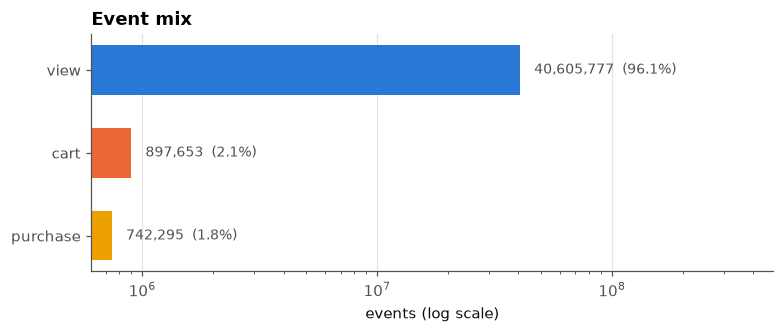

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.8))
order = mix.sort("events")
bars = ax.barh(order["event_type"], order["events"], height=0.6,
               color=[EVENT_COLOURS[e] for e in order["event_type"]])
ax.set_xscale("log")
ax.grid(axis="y", visible=False)
for bar, n, s in zip(bars, order["events"], order["share"]):
    ax.text(bar.get_width() * 1.15, bar.get_y() + bar.get_height() / 2, f"{n:,}  ({s:.1%})",
            va="center", fontsize=9, color=INK_MUTED)
ax.set_xlim(right=order["events"].max() * 12)
ax.set_xlabel("events (log scale)")
ax.set_title("Event mix")
save_figure(fig, cfg, "eda_event_mix")
plt.show()

## 3. Activity over time

Daily volume per event type (log scale, so the rare types stay visible) and the
hour-of-day / day-of-week profile used by the G5 time features. Timestamps are UTC.

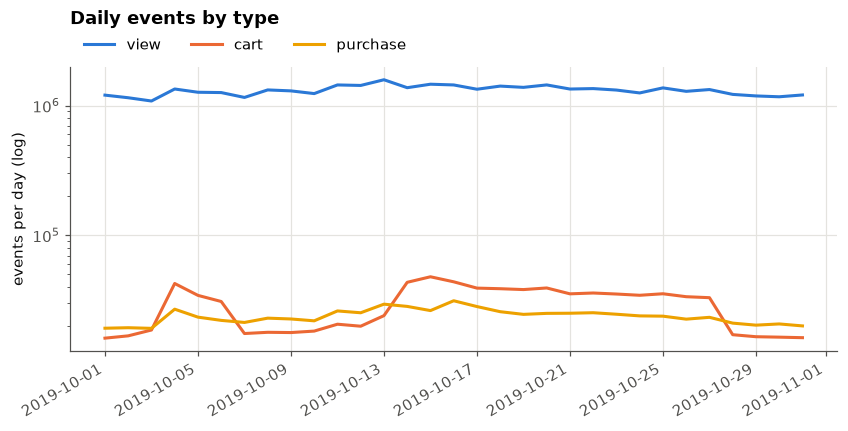

In [5]:
daily = (
    events.group_by(pl.col("event_time").dt.date().alias("day"), "event_type").agg(n=pl.len())
    .collect(engine="streaming").with_columns(pl.col("event_type").cast(pl.String)).sort("day")
)
fig, ax = plt.subplots(figsize=(9, 3.8))
for et in EVENT_TYPES:
    d = daily.filter(pl.col("event_type") == et)
    if d.height:
        ax.plot(d["day"], d["n"], color=EVENT_COLOURS[et], label=et)
ax.set_yscale("log")
ax.set_ylabel("events per day (log)")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Daily events by type", pad=28)
fig.autofmt_xdate()
save_figure(fig, cfg, "eda_daily_events")
plt.show()

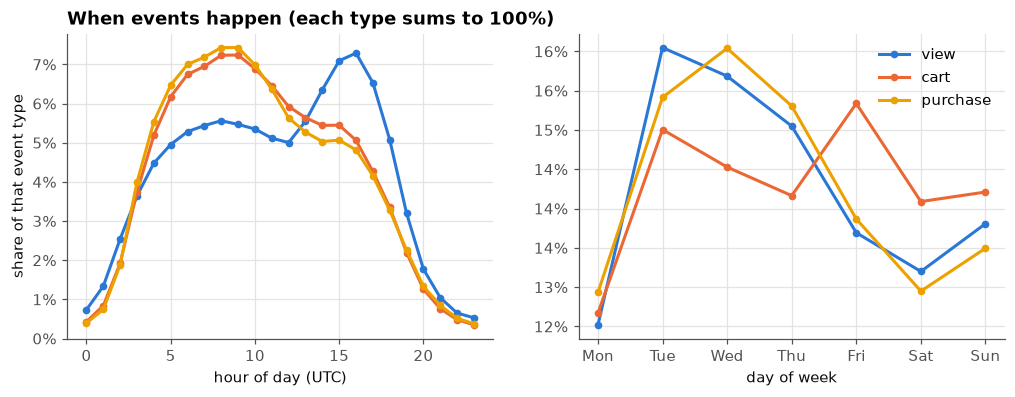

In [6]:
profile = (
    events.group_by(pl.col("event_time").dt.hour().alias("hour"),
                    pl.col("event_time").dt.weekday().alias("weekday"), "event_type")
    .agg(n=pl.len()).collect(engine="streaming").with_columns(pl.col("event_type").cast(pl.String))
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, col, labels in [(axes[0], "hour", None), (axes[1], "weekday", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])]:
    for et in ("view", "cart", "purchase"):
        p = (profile.filter(pl.col("event_type") == et).group_by(col).agg(pl.col("n").sum()).sort(col)
             .with_columns(share=pl.col("n") / pl.col("n").sum()))
        ax.plot(p[col], p["share"], marker="o", markersize=4, color=EVENT_COLOURS[et], label=et)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("hour of day (UTC)" if col == "hour" else "day of week")
    if labels:
        ax.set_xticks(range(1, 8), labels)
axes[0].set_ylabel("share of that event type")
axes[0].set_title("When events happen (each type sums to 100%)")
axes[1].legend()
save_figure(fig, cfg, "eda_time_profile")
plt.show()

## 4. Sessions

One row per session, with events ordered exactly as the pipeline orders them
(`index_events`: time, then funnel order, then product). This table is for analysis
only — it looks at whole sessions, including their future.

In [7]:
indexed = index_events(events)
sess = (
    indexed.group_by("user_session").agg(
        user_id=pl.col("user_id").first(),
        start=pl.col("event_time").min(),
        end=pl.col("event_time").max(),
        n_events=pl.len(),
        n_carts=(pl.col("event_type") == "cart").sum(),
        n_purchases=(pl.col("event_type") == "purchase").sum(),
        n_products=pl.col("product_id").n_unique(),
        first_cart_pos=pl.col("pos").filter(pl.col("event_type") == "cart").min(),
        first_purchase_pos=pl.col("pos").filter(pl.col("event_type") == "purchase").min(),
    )
    .with_columns(
        duration_sec=(pl.col("end") - pl.col("start")).dt.total_seconds(),
        carted=pl.col("n_carts") > 0,
        bought=pl.col("n_purchases") > 0,
    )
    .collect(engine="streaming")
)
n_sessions = sess.height
display(sess.select("n_events", "n_products", "duration_sec").describe(
    percentiles=(0.25, 0.5, 0.75, 0.9, 0.99)))
summary["sessions"] = {
    "n": n_sessions,
    "median_events": float(sess["n_events"].median()),
    "single_event_share": float((sess["n_events"] == 1).mean()),
    "purchase_session_share": float(sess["bought"].mean()),
    "cart_session_share": float(sess["carted"].mean()),
}
summary["sessions"]

statistic,n_events,n_products,duration_sec
str,f64,f64,f64
"""count""",9.222333e6,9.222333e6,9.222333e6
"""null_count""",0.0,0.0,0.0
"""mean""",4.580807,3.003003,370.074365
"""std""",6.729333,4.156635,"2,259.586204"
"""min""",1.0,1.0,0.0
"""25%""",1.0,1.0,0.0
"""50%""",2.0,1.0,63.0
"""75%""",5.0,3.0,267.0
"""90%""",10.0,7.0,706.0


{'n': 9222333,
 'median_events': 2.0,
 'single_event_share': 0.35454803030859977,
 'purchase_session_share': 0.06824119233170176,
 'cart_session_share': 0.06209838660130793}

**How many sessions are long enough?** A session needs *more than K* events to have a
future to predict. The curve below is the share of sessions with more than *n* events;
the dashed lines are the configured K values.

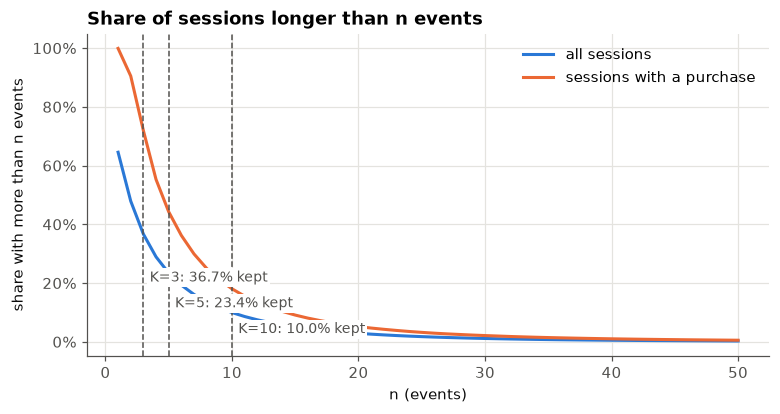

In [8]:
max_n = 50
lengths = sess["n_events"].to_numpy()
ns = np.arange(1, max_n + 1)
survive = np.array([(lengths > n).mean() for n in ns])
buyers = sess.filter(pl.col("bought"))["n_events"].to_numpy()
survive_buy = np.array([(buyers > n).mean() for n in ns]) if buyers.size else np.zeros_like(survive)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ns, survive, color=TARGET_COLOURS[0], label="all sessions")
ax.plot(ns, survive_buy, color=TARGET_COLOURS[1], label="sessions with a purchase")
for i, k in enumerate(KS):
    ax.axvline(k, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.text(k + 0.5, 0.06 + 0.08 * (len(KS) - 1 - i), f"K={k}: {(lengths > k).mean():.1%} kept", fontsize=9, color=INK_MUTED,
            transform=ax.get_xaxis_transform(), va="bottom", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("n (events)")
ax.set_ylabel("share with more than n events")
ax.set_title("Share of sessions longer than n events")
ax.legend()
save_figure(fig, cfg, "eda_session_length")
plt.show()
summary["share_longer_than_k"] = {str(k): float((lengths > k).mean()) for k in KS}

**Funnel and the cart signal.** Purchase rate of sessions with and without a cart
event, and by total session length (the length bins used later for error analysis).

carted,sessions,purchase_rate
bool,u32,f64
false,"8,649,641",0.039033
true,"572,692",0.509392


length,sessions,purchase_rate
str,u32,f64
"""[0, 10)""","8,152,866",0.060884
"""[10, 20)""","772,866",0.125088
"""[20, 50)""","270,014",0.12102
"""[50, inf)""","26,587",0.135931


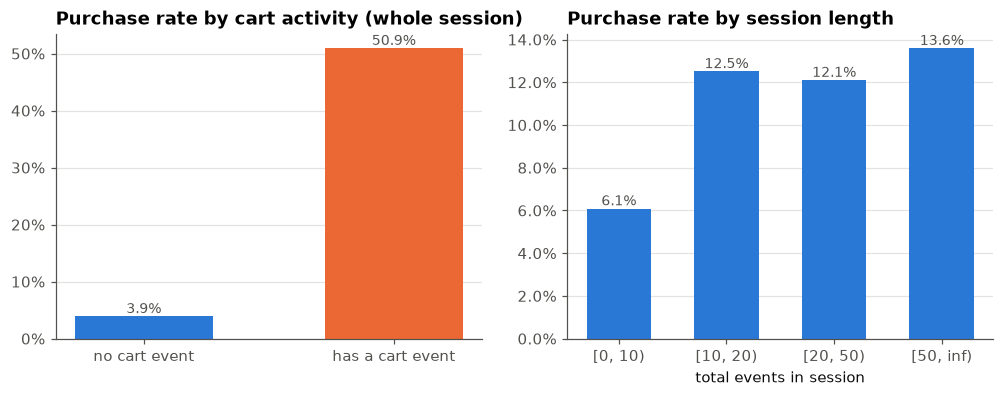

In [9]:
def length_bin(col: str, edges) -> pl.Expr:
    expr = None
    for lo, hi in zip(edges[:-1], edges[1:]):
        label = f"[{lo:g}, {hi:g})"
        cond = (pl.col(col) >= lo) & (pl.col(col) < hi)
        expr = pl.when(cond).then(pl.lit(label)) if expr is None else expr.when(cond).then(pl.lit(label))
    return expr.otherwise(pl.lit("other"))

by_cart = sess.group_by("carted").agg(sessions=pl.len(), purchase_rate=pl.col("bought").mean()).sort("carted")
by_len = (sess.with_columns(length=length_bin("n_events", LENGTH_EDGES))
          .group_by("length").agg(sessions=pl.len(), purchase_rate=pl.col("bought").mean(),
                                  min_len=pl.col("n_events").min()).sort("min_len").drop("min_len"))
display(by_cart, by_len)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labels = ["no cart event", "has a cart event"]
rates = [by_cart.filter(pl.col("carted") == c)["purchase_rate"].item() if c in by_cart["carted"] else 0.0
         for c in (False, True)]
axes[0].bar(labels, rates, width=0.55, color=[TARGET_COLOURS[0], TARGET_COLOURS[1]])
axes[0].set_title("Purchase rate by cart activity (whole session)")
axes[1].bar(by_len["length"], by_len["purchase_rate"], width=0.6, color=PALETTE[0])
axes[1].set_title("Purchase rate by session length")
axes[1].set_xlabel("total events in session")
for ax, vals in ((axes[0], rates), (axes[1], by_len["purchase_rate"].to_list())):
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", visible=False)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=INK_MUTED)
save_figure(fig, cfg, "eda_purchase_rate_cart_length")
plt.show()
summary["purchase_rate_given_cart"] = rates[1]
summary["purchase_rate_given_no_cart"] = rates[0]

## 5. When does the first purchase happen?

The trade-off behind RQ2. A larger K gives the model more evidence, but every buying
session whose first purchase falls inside the first K events is dropped (the outcome
is already known), and sessions with K or fewer events are dropped too.

In [10]:
buy = sess.filter(pl.col("bought"))
fpp = buy["first_purchase_pos"].to_numpy()
rows = []
for k in KS:
    rows.append({
        "K": k,
        "buying_sessions": buy.height,
        "first_purchase_within_K": float((fpp <= k).mean()) if fpp.size else 0.0,
        "usable_as_positive": float((fpp > k).mean()) if fpp.size else 0.0,
    })
k_tradeoff = pl.DataFrame(rows)
display(k_tradeoff)
summary["first_purchase_pos_median"] = float(np.median(fpp)) if fpp.size else None

gap = buy.filter(pl.col("first_cart_pos").is_not_null()).select(
    cart_before_purchase=(pl.col("first_cart_pos") < pl.col("first_purchase_pos")).mean(),
    median_events_cart_to_purchase=(pl.col("first_purchase_pos") - pl.col("first_cart_pos")).median(),
)
display(gap)
summary["buyers_with_cart_first"] = float(gap["cart_before_purchase"].item() or 0.0) if gap.height else None

K,buying_sessions,first_purchase_within_K,usable_as_positive
i64,i64,f64,f64
3,"629,343",0.50676,0.49324
5,"629,343",0.717618,0.282382
10,"629,343",0.891255,0.108745


cart_before_purchase,median_events_cart_to_purchase
f64,f64
0.961611,1.0


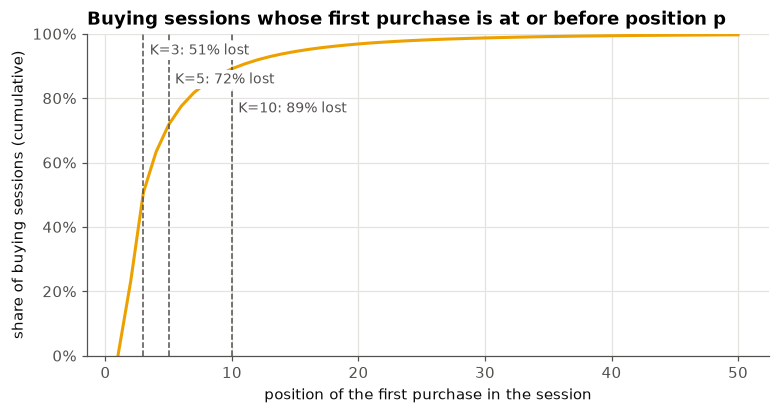

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
if fpp.size:
    ps = np.arange(1, max_n + 1)
    ax.plot(ps, [(fpp <= p).mean() for p in ps], color=EVENT_COLOURS["purchase"])
    for i, k in enumerate(KS):
        ax.axvline(k, color=INK_MUTED, linestyle="--", linewidth=1)
        ax.text(k + 0.5, 0.97 - 0.09 * i, f"K={k}: {(fpp <= k).mean():.0%} lost", fontsize=9, color=INK_MUTED,
                va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_xlabel("position of the first purchase in the session")
ax.set_ylabel("share of buying sessions (cumulative)")
ax.set_title("Buying sessions whose first purchase is at or before position p")
save_figure(fig, cfg, "eda_first_purchase_position")
plt.show()

## 6. Eligibility at each K (the modelling population)

From the reports written by `src/data/sessionize.py`. *Base rate* = positive share of
eligible sessions. It changes with K, which is why RQ2 compares PR-AUC **lift**
(PR-AUC ÷ base rate) as well as PR-AUC.

k,sessions_total,too_short,purchase_within_prefix,eligible,positives,positive_rate,eligible_share,imbalance
i64,i64,i64,i64,i64,i64,f64,f64,f64
3,"9,222,333","5,840,170","142,173","3,239,990","310,417",0.095808,0.35132,9.43754
5,"9,222,333","7,061,595","100,913","2,059,825","177,715",0.086277,0.223352,10.590609
10,"9,222,333","8,303,899","45,189","873,245","68,438",0.078372,0.094688,11.759651


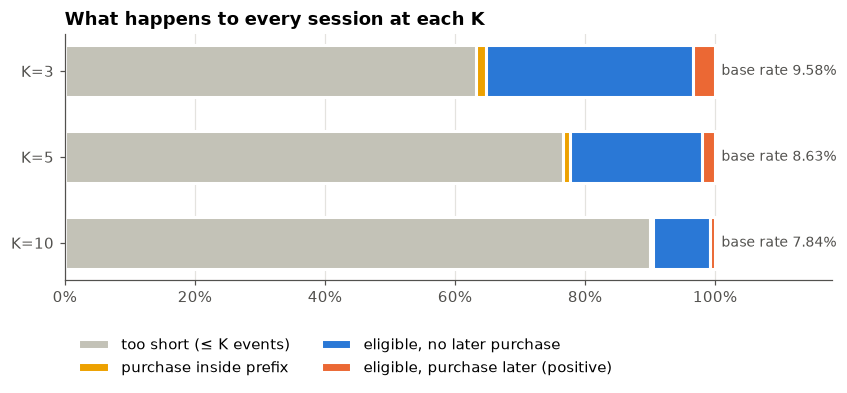

In [12]:
funnel = pl.DataFrame([json.loads((processed_dir_for_k(cfg, k) / "sessionize_report.json").read_text()) for k in KS])
funnel = funnel.select("k", "sessions_total", "too_short", "purchase_within_prefix", "eligible", "positives",
                       "positive_rate").with_columns(eligible_share=pl.col("eligible") / pl.col("sessions_total"),
                                                     imbalance=(pl.col("eligible") - pl.col("positives"))
                                                     / pl.col("positives").clip(lower_bound=1))
display(funnel)
summary["eligibility"] = {str(r["k"]): r for r in funnel.iter_rows(named=True)}

parts = [("too short (≤ K events)", funnel["too_short"], "#c3c2b7"),
         ("purchase inside prefix", funnel["purchase_within_prefix"], EVENT_COLOURS["purchase"]),
         ("eligible, no later purchase", funnel["eligible"] - funnel["positives"], TARGET_COLOURS[0]),
         ("eligible, purchase later (positive)", funnel["positives"], TARGET_COLOURS[1])]
fig, ax = plt.subplots(figsize=(9, 2.9))
left = np.zeros(len(KS))
y = [f"K={k}" for k in KS]
for label, vals, colour in parts:
    share = vals.to_numpy() / funnel["sessions_total"].to_numpy()
    ax.barh(y, share, left=left, height=0.6, color=colour, label=label, edgecolor="white", linewidth=2)
    left += share
for i, r in enumerate(funnel.iter_rows(named=True)):
    ax.text(1.01, i, f"base rate {r['positive_rate']:.2%}", va="center", fontsize=9, color=INK_MUTED)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1.18)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, -0.18))
ax.set_title("What happens to every session at each K")
save_figure(fig, cfg, "eda_eligibility_by_k")
plt.show()

## 7. Returning users across the split

The split is chronological by session start, so one user can have sessions in both
train and test. That is not label leakage (no future events enter a prefix), but it
means test performance partly reflects users the model has already seen. Reported as
a threat to validity.

In [13]:
per_user = sess.group_by("user_id").agg(sessions=pl.len(), buys=pl.col("bought").sum())
display(per_user.select(
    users=pl.len(),
    multi_session_users=(pl.col("sessions") > 1).mean(),
    median_sessions=pl.col("sessions").median(),
    repeat_buyers=(pl.col("buys") > 1).mean(),
))

split_sessions = load_split_sessions(cfg, K0).select("user_id", "split").collect()
train_users = split_sessions.filter(pl.col("split") == "train")["user_id"].unique()
overlap = (split_sessions.filter(pl.col("split") == "test")
           .select(seen_in_train=pl.col("user_id").is_in(train_users.implode()).mean()).item())
print(f"K={K0}: {overlap:.1%} of test sessions belong to users who also have a train session")
summary["test_sessions_with_train_user"] = float(overlap or 0.0)

users,multi_session_users,median_sessions,repeat_buyers
u32,f64,f64,f64
"3,017,263",0.510969,2.0,0.036996


K=5: 45.6% of test sessions belong to users who also have a train session


## 8. Categories, brands and prices

`category_code` is a dotted path; its first part is `main_category` (G4). Missing codes
and brands were filled with the `unknown` token during cleaning.

In [14]:
missing = events.select(
    missing_category=(pl.col("category_code") == UNKNOWN_CAT).mean(),
    missing_brand=(pl.col("brand") == UNKNOWN_BRAND).mean(),
).collect(engine="streaming")
display(missing)
summary["missing_share"] = missing.row(0, named=True)

cats = (
    events.with_columns(main_category=pl.col("category_code").str.split(".").list.first())
    .group_by("main_category")
    .agg(events=pl.len(),
         views=(pl.col("event_type") == "view").sum(),
         purchases=(pl.col("event_type") == "purchase").sum())
    .with_columns(purchases_per_1k_views=1000 * pl.col("purchases") / pl.col("views").clip(lower_bound=1))
    .sort("events", descending=True)
    .collect(engine="streaming")
)
display(cats.head(15))

missing_category,missing_brand
f64,f64
0.318292,0.142774


main_category,events,views,purchases,purchases_per_1k_views
str,u32,u32,u32,f64
"""electronics""","16,050,827","14,975,544","422,670",28.224016
"""unknown""","13,446,464","13,170,249","173,347",13.162014
"""appliances""","4,952,446","4,788,226","74,928",15.648384
"""computers""","2,312,048","2,257,432","27,817",12.322409
"""apparel""","1,536,544","1,528,521","8,000",5.233818
"""furniture""","1,240,576","1,229,949","8,298",6.746621
"""auto""","1,010,490","990,960","10,616",10.712844
"""construction""","728,736","710,871","7,800",10.972455
"""kids""","518,285","510,271","5,481",10.741351


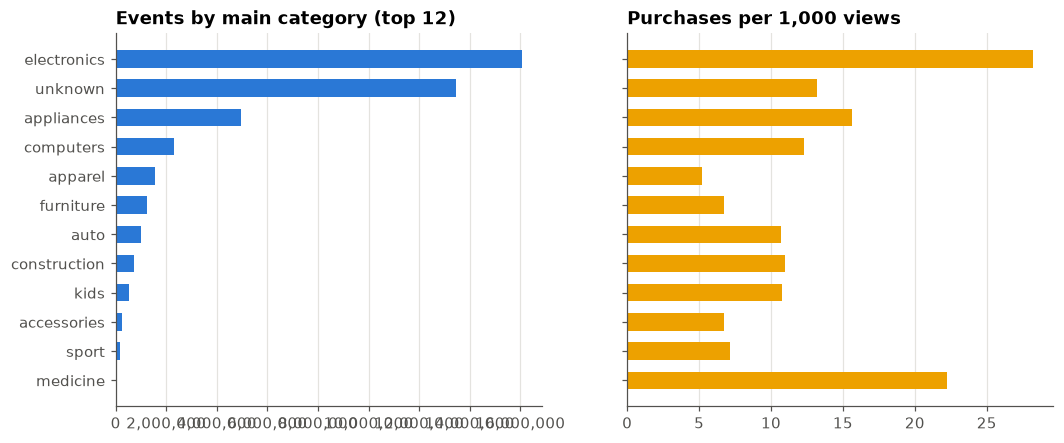

In [15]:
top = cats.head(12).reverse()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
axes[0].barh(top["main_category"], top["events"], height=0.6, color=PALETTE[0])
axes[0].xaxis.set_major_formatter(thousands)
axes[0].set_title("Events by main category (top 12)")
axes[1].barh(top["main_category"], top["purchases_per_1k_views"], height=0.6, color=EVENT_COLOURS["purchase"])
axes[1].set_title("Purchases per 1,000 views")
for ax in axes:
    ax.grid(axis="y", visible=False)
save_figure(fig, cfg, "eda_categories")
plt.show()

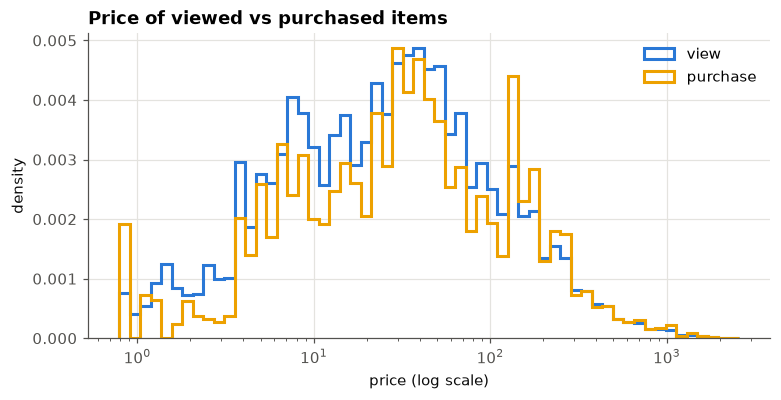

event_type,median_price,mean_price
enum,f64,f64
"""view""",161.76,289.369658
"""cart""",197.14,334.774467
"""purchase""",179.83,309.534342


In [16]:
price = (events.filter(pl.col("event_type").is_in(["view", "purchase"]))
         .select("event_type", "price").collect(engine="streaming"))
if price.height > 1_000_000:  # histogram shape only; a sample is enough
    price = price.sample(1_000_000, seed=cfg["project"]["seeds"][0])
bins = np.logspace(np.log10(max(price["price"].min(), 0.01)), np.log10(price["price"].max()), 60)
fig, ax = plt.subplots(figsize=(8, 3.6))
for et in ("view", "purchase"):
    vals = price.filter(pl.col("event_type").cast(pl.String) == et)["price"].to_numpy()
    if vals.size:
        ax.hist(vals, bins=bins, density=True, histtype="step", linewidth=2, color=EVENT_COLOURS[et], label=et)
ax.set_xscale("log")
ax.set_xlabel("price (log scale)")
ax.set_ylabel("density")
ax.set_title("Price of viewed vs purchased items")
ax.legend()
save_figure(fig, cfg, "eda_price")
plt.show()
display(events.group_by("event_type").agg(median_price=pl.col("price").median(), mean_price=pl.col("price").mean())
        .collect(engine="streaming").sort("event_type"))

## 9. Purchase rate over time and the split

Daily base rate of eligible sessions at the default K, with the shared cut-offs.
A drifting rate means the test period is harder or easier than validation, which is
one reason thresholds are tuned on validation and reported on test.

In [17]:
cutoffs = json.loads(cutoffs_path(cfg).read_text())
print({k: v for k, v in cutoffs.items()})
split_table = pl.DataFrame([
    {"K": k, "split": s, **{f: r[s][f] for f in ("sessions", "fraction", "positive_rate")}}
    for k in KS
    for r in [json.loads((processed_dir_for_k(cfg, k) / "split_report.json").read_text())]
    for s in ("train", "val", "test") if s in r
])
display(split_table)
summary["splits"] = split_table.to_dicts()

{'computed_from_k': 3, 'n_sessions': 3239990, 'val_start': '2019-10-22T08:26:45+00:00', 'test_start': '2019-10-26T19:59:30+00:00'}


K,split,sessions,fraction,positive_rate
i64,str,i64,f64,f64
3,"""train""","2,266,794",0.70001,0.096884
3,"""val""","485,437",0.149908,0.098
3,"""test""","485,999",0.150082,0.088545
5,"""train""","1,440,479",0.699803,0.08734
5,"""val""","308,271",0.149762,0.08861
5,"""test""","309,656",0.150435,0.078926
10,"""train""","609,845",0.699072,0.079304
10,"""val""","130,589",0.149696,0.080221
10,"""test""","131,930",0.151233,0.072137


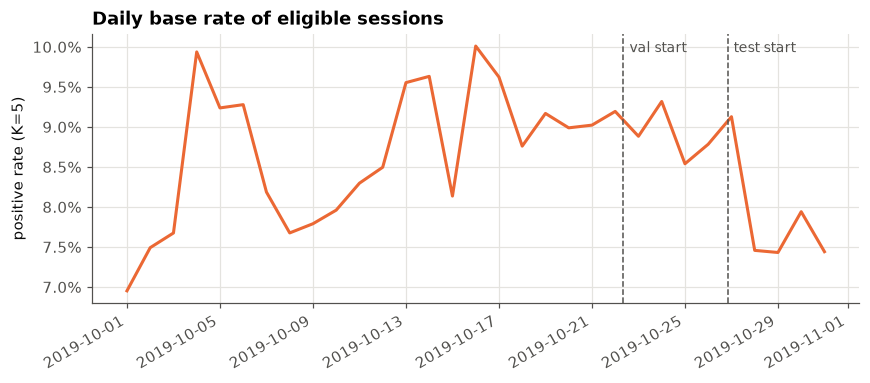

In [18]:
from datetime import datetime

daily_rate = (load_split_sessions(cfg, K0)
              .group_by(pl.col("session_start").dt.date().alias("day"))
              .agg(sessions=pl.len(), rate=pl.col(TARGET).mean()).sort("day").collect())
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(daily_rate["day"], daily_rate["rate"], color=TARGET_COLOURS[1])
for name in ("val_start", "test_start"):
    t = datetime.fromisoformat(cutoffs[name])
    ax.axvline(t, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.annotate(name.replace("_", " "), (t, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points",
                fontsize=9, color=INK_MUTED)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_ylabel(f"positive rate (K={K0})")
ax.set_title("Daily base rate of eligible sessions")
fig.autofmt_xdate()
save_figure(fig, cfg, "eda_base_rate_over_time")
plt.show()

## 10. First look at the prefix

Only the first K events — exactly what a model sees. Purchase rate by the number of
cart events in the prefix is the signal behind the rule baseline (`cart_count > 0`)
and H5 (cart signals rank first). Feature-level detail is in `02_feature_analysis`.

carts_in_prefix,sessions,purchase_rate,K
str,u32,f64,i32
"""0""","3,059,123",0.072796,3
"""1""","149,166",0.464576,3
"""2""","29,773",0.609881,3
"""3+""",168,0.428571,3
"""0""","1,933,485",0.06614,5
"""1""","82,694",0.334583,5
"""2""","30,135",0.511067,5
"""3+""","12,092",0.547304,5
"""0""","816,592",0.063163,10


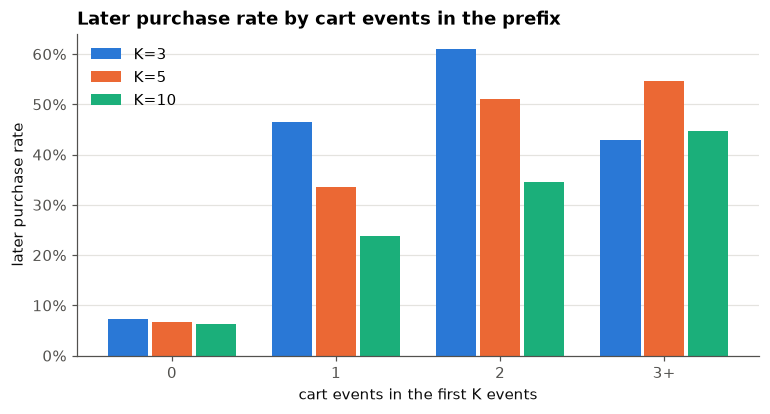

In [19]:
rows = []
for k in KS:
    pre = pl.scan_parquet(processed_dir_for_k(cfg, k) / "prefix_events.parquet")
    carts = pre.group_by("user_session").agg(carts=(pl.col("event_type") == "cart").sum())
    t = (load_split_sessions(cfg, k).select("user_session", TARGET).join(carts, on="user_session")
         .with_columns(carts_in_prefix=pl.when(pl.col("carts") >= 3).then(pl.lit("3+"))
                       .otherwise(pl.col("carts").cast(pl.String)))
         .group_by("carts_in_prefix").agg(sessions=pl.len(), purchase_rate=pl.col(TARGET).mean())
         .with_columns(K=pl.lit(k)).collect())
    rows.append(t)
cart_signal = pl.concat(rows).sort("K", "carts_in_prefix")
display(cart_signal)

levels = ["0", "1", "2", "3+"]
width = 0.8 / len(KS)
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, k in enumerate(KS):
    d = {r["carts_in_prefix"]: r["purchase_rate"] for r in cart_signal.filter(pl.col("K") == k).iter_rows(named=True)}
    ax.bar(np.arange(len(levels)) + (i - (len(KS) - 1) / 2) * width, [d.get(l, np.nan) for l in levels],
           width=width * 0.92, color=PALETTE[i], label=f"K={k}")
ax.set_xticks(range(len(levels)), levels)
ax.set_xlabel("cart events in the first K events")
ax.set_ylabel("later purchase rate")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.legend()
ax.set_title("Later purchase rate by cart events in the prefix")
save_figure(fig, cfg, "eda_cart_signal")
plt.show()
summary["cart_signal"] = cart_signal.to_dicts()

## 11. Key numbers

Printed from the data (nothing hard-coded), and saved for the report.

In [20]:
e = summary["eligibility"]
lines = [
    f"{summary['sessions']['n']:,} sessions; median length {summary['sessions']['median_events']:.0f} events, "
    f"{summary['sessions']['single_event_share']:.1%} have a single event.",
    f"{summary['sessions']['purchase_session_share']:.2%} of sessions contain a purchase; "
    f"{summary['sessions']['cart_session_share']:.2%} contain a cart event.",
    f"Purchase rate with a cart event {summary['purchase_rate_given_cart']:.1%} vs "
    f"{summary['purchase_rate_given_no_cart']:.2%} without.",
    "Eligible sessions / base rate: " + "; ".join(
        f"K={k}: {e[str(k)]['eligible']:,} / {e[str(k)]['positive_rate']:.2%}" for k in KS) + ".",
    "Buying sessions lost because the first purchase is inside the prefix: " + "; ".join(
        f"K={r['K']}: {r['first_purchase_within_K']:.0%}" for r in k_tradeoff.iter_rows(named=True)) + ".",
    f"{summary['test_sessions_with_train_user']:.1%} of K={K0} test sessions come from users seen in training.",
]
print("\n".join(f"- {line}" for line in lines))

out = resolve_path(cfg, "tables_dir") / f"eda_summary_{MODE}.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(summary, indent=2, default=str))
print(f"\nsaved {out}")

- 9,222,333 sessions; median length 2 events, 35.5% have a single event.
- 6.82% of sessions contain a purchase; 6.21% contain a cart event.
- Purchase rate with a cart event 50.9% vs 3.90% without.
- Eligible sessions / base rate: K=3: 3,239,990 / 9.58%; K=5: 2,059,825 / 8.63%; K=10: 873,245 / 7.84%.
- Buying sessions lost because the first purchase is inside the prefix: K=3: 51%; K=5: 72%; K=10: 89%.
- 45.6% of K=5 test sessions come from users seen in training.

saved /Users/karan/Documents/NCI/Machine Learning/Project/E Commerce ML/results/tables/eda_summary_dev.json
